
# Data Visualization — Turning Retail Sales Data into a Visual Story

## Project Overview
This project analyses retail customer sales data to identify sales trends, regional performance, customer demographics, profitability, and customer satisfaction.

## Dataset
- Source: Retail Customer Sales Dataset
- Records: Approximately 7,000 transactions
- Time Period: 2023–2024 
- Regions: North, South, East, West
- Columns: 24

## Objectives
1. Analyse overall sales and profitability.
2. Compare regional and product category performance.
3. Understand customer demographics.
4. Investigate relationships between discounts, sales, and profit.
5. Explore customer satisfaction and product returns.
6. Create meaningful visualisations and business insights.

## Tools & Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly and Jupyter Notebook.


In [2]:
pip install pandas numpy matplotlib seaborn plotly openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_excel(r"C:\Users\hp\Desktop\Esha_Data_project_MCA(1A)\Cleaned_retail_customer_sales_dataset.xlsx")
print("Dataset loaded successfully, Good to go!")

Dataset loaded successfully, Good to go!


In [5]:
df.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,North,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


In [6]:
df.shape

(7000, 24)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      7000 non-null   object        
 1   Customer_ID         7000 non-null   object        
 2   Order_Date          7000 non-null   datetime64[ns]
 3   Delivery_Date       6895 non-null   datetime64[ns]
 4   Age                 6854 non-null   float64       
 5   Gender              7000 non-null   object        
 6   Income              6755 non-null   float64       
 7   Region              7000 non-null   object        
 8   State               7000 non-null   object        
 9   City                7000 non-null   object        
 10  Customer_Segment    7000 non-null   object        
 11  Product_Category    7000 non-null   object        
 12  Product             7000 non-null   object        
 13  Quantity            7000 non-null   int64       

In [8]:
df.describe()

,Order_Date,Delivery_Date,Age,Income,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Customer_Rating
count,7000,6895,6854.000000,6.755000e+03,7000.000000,7000.000000,6924.000000,7000.000000,7000.000000,7000.000000,6580.000000
mean,2023-12-29 10:42:14.400000256,2024-01-03 21:33:10.833937664,36.063612,5.510138e+04,3.009714,4519.225109,0.200205,10961.598467,7371.900944,3589.697523,3.092401
min,2023-01-01 00:00:00,2023-01-02 00:00:00,18.000000,1.500000e+04,1.000000,51.530000,0.000000,28.700000,19.530000,9.170000,1.000000
25%,2023-06-28 00:00:00,2023-07-04 00:00:00,29.000000,3.712540e+04,2.000000,895.922500,0.110000,1815.460000,1210.180000,574.082500,2.000000
50%,2023-12-28 00:00:00,2024-01-02 00:00:00,36.000000,4.900517e+04,3.000000,2261.470000,0.180000,4825.555000,3229.885000,1528.695000,3.000000
75%,2024-06-30 00:00:00,2024-07-05 00:00:00,43.000000,6.572173e+04,4.000000,7244.505000,0.270000,14095.345000,9494.697500,4533.285000,4.000000
max,2024-12-31 00:00:00,2025-01-13 00:00:00,72.000000,1.750890e+06,10.000000,19989.990000,0.500000,122950.970000,81532.800000,47233.610000,5.000000
std,NaN,NaN,10.418153,3.733842e+04,1.410538,4893.207470,0.117106,14549.034144,9877.999500,4928.020031,1.010345


In [9]:
df.isnull().sum()

Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         105
Age                   146
Gender                  0
Income                245
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               76
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       420
Satisfaction_Level    175
Returned                0
dtype: int64

In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicated transaction IDs:", df["Transaction_ID"].duplicated().sum())

Duplicate rows: 0
Duplicated transaction IDs: 0


In [11]:
df.columns.tolist()

['Transaction_ID',
 'Customer_ID',
 'Order_Date',
 'Delivery_Date',
 'Age',
 'Gender',
 'Income',
 'Region',
 'State',
 'City',
 'Customer_Segment',
 'Product_Category',
 'Product',
 'Quantity',
 'Unit_Price',
 'Discount',
 'Sales',
 'Cost',
 'Profit',
 'Payment_Method',
 'Delivery_Mode',
 'Customer_Rating',
 'Satisfaction_Level',
 'Returned']

## Data Quality Verification

Before creating visualisations, verify that the cleaned dataset has loaded correctly into Python. Check the dataset dimensions, data types, missing values, duplicates, date range, and important data-quality issues.

In [12]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column data types
print("\nData Types:")
display(df.dtypes)

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Duplicate transaction IDs
print("Duplicate Transaction IDs:",
      df["Transaction_ID"].duplicated().sum())

# Order date range
print("\nOrder Date Range:")
print(df["Order_Date"].min(), "to", df["Order_Date"].max())

# Check delivery dates earlier than order dates
invalid_delivery = df[
    df["Delivery_Date"].notna() &
    (df["Delivery_Date"] < df["Order_Date"])
]

print("\nDelivery Dates Earlier Than Order Dates:",
      len(invalid_delivery))

Dataset Shape: (7000, 24)

Data Types:


Transaction_ID                object
Customer_ID                   object
Order_Date            datetime64[ns]
Delivery_Date         datetime64[ns]
Age                          float64
Gender                        object
Income                       float64
Region                        object
State                         object
City                          object
Customer_Segment              object
Product_Category              object
Product                       object
Quantity                       int64
Unit_Price                   float64
Discount                     float64
Sales                        float64
Cost                         float64
Profit                       float64
Payment_Method                object
Delivery_Mode                 object
Customer_Rating              float64
Satisfaction_Level            object
Returned                      object
dtype: object


Missing Values:


Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         105
Age                   146
Gender                  0
Income                245
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               76
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       420
Satisfaction_Level    175
Returned                0
dtype: int64


Duplicate Rows: 0
Duplicate Transaction IDs: 0

Order Date Range:
2023-01-01 00:00:00 to 2024-12-31 00:00:00

Delivery Dates Earlier Than Order Dates: 15


## Data Preparation for Visualisation

Prepare date-based and numerical fields for analysis. Create a monthly period column and a year column to support time-series analysis. The original dataset will remain unchanged.

In [13]:
# Convert date columns to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")

# Create year and month columns
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["Year_Month"] = df["Order_Date"].dt.to_period("M")

# Set visualisation style
sns.set_theme(style="whitegrid", palette="deep")

# Create output folder if it does not exist
import os

os.makedirs("../visualizations", exist_ok=True)

print("Data preparation completed.")

Data preparation completed.


## Key Business Performance Indicators

Calculate the main business metrics to understand the overall performance of the retail dataset. These include total sales, total profit, profit margin, and average order value.

In [14]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

average_order_value = (
    df.groupby("Transaction_ID")["Sales"].sum().mean()
)

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

Total Sales: ₹76,731,189.27
Total Profit: ₹25,127,882.66
Profit Margin: 32.75%
Average Order Value: ₹10,961.60


## 1. Monthly Sales Trend

Analyse monthly sales performance from 2023 to 2024 to identify trends, seasonal patterns, and high-performing months.

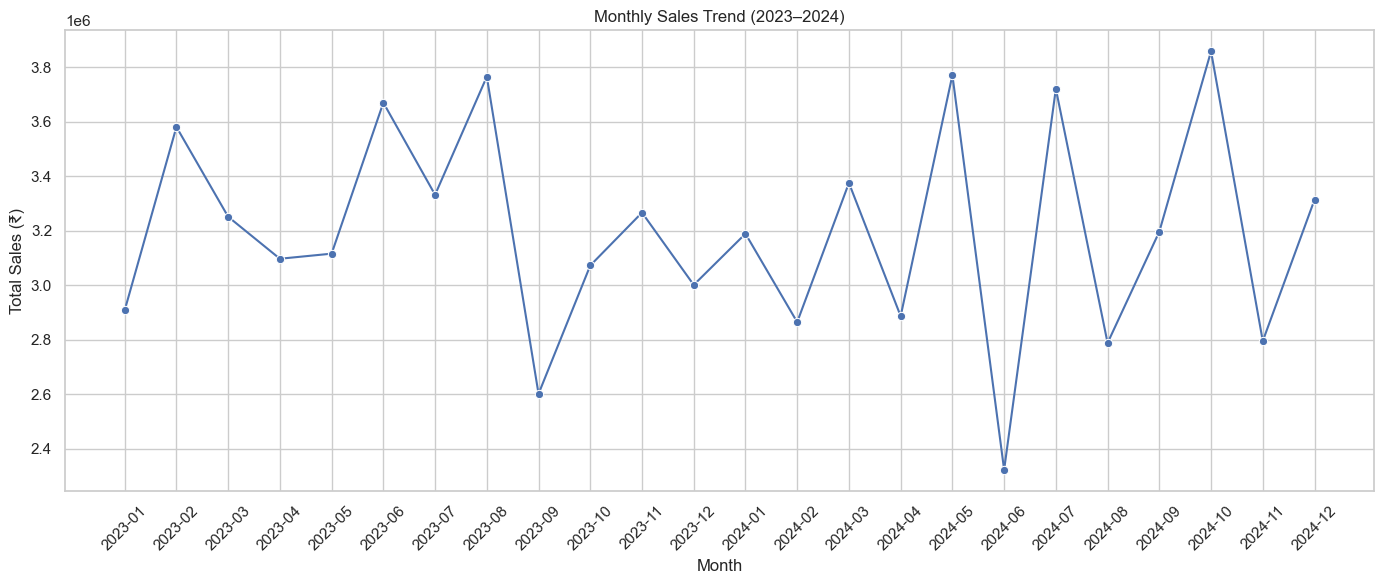

In [15]:
monthly_sales = (
    df.groupby("Year_Month")["Sales"]
    .sum()
    .reset_index()
)

monthly_sales["Month"] = monthly_sales["Year_Month"].astype(str)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2023–2024)")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../visualizations/01_monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 2. Total Sales by Region

Compare sales performance across the four geographical regions to identify the strongest and weakest markets.

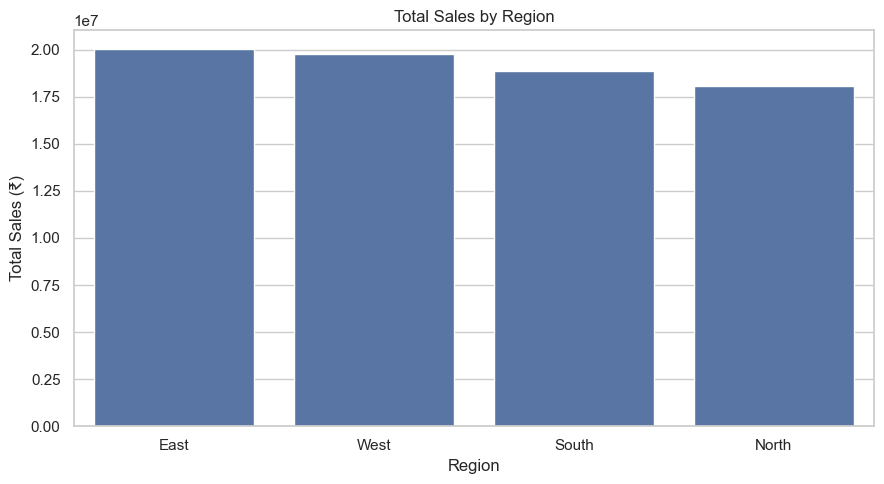

In [16]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (₹)")

plt.tight_layout()
plt.savefig("../visualizations/02_sales_by_region.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 3. Total Sales by Product Category

Compare the contribution of different product categories to overall retail sales.

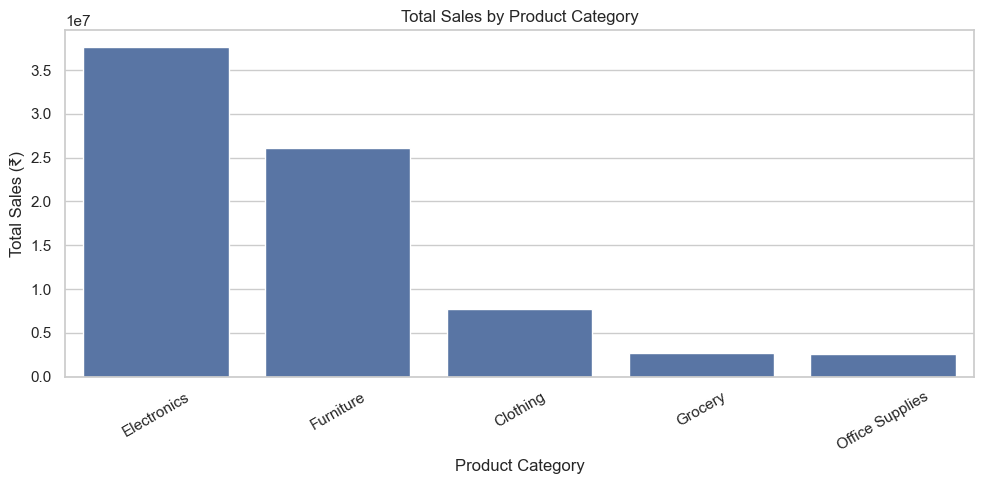

In [17]:
category_sales = (
    df.groupby("Product_Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("../visualizations/03_sales_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 4. Customer Age Distribution

Examine the age distribution of customers to understand the demographic composition of the customer base.

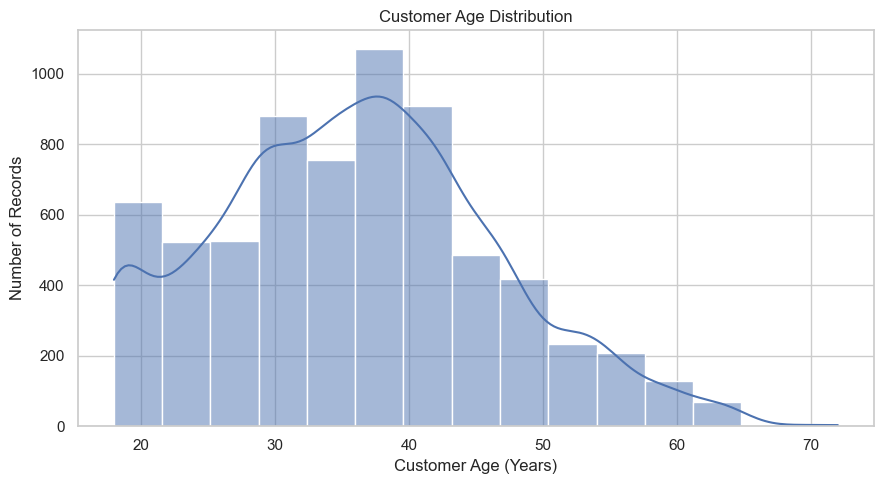

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age (Years)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("../visualizations/04_customer_age_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 5. Customer Income Distribution

Examine customer income distribution and identify its overall shape, skewness, and unusually high income values.

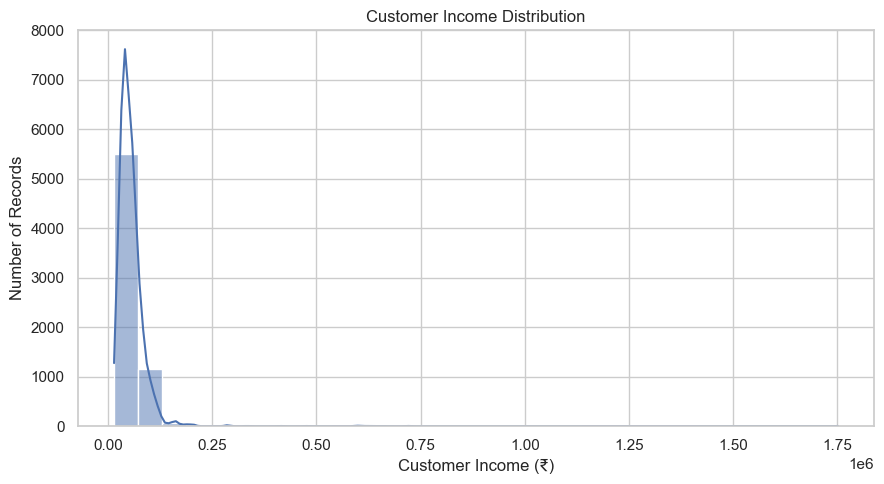

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Income",
    bins=30,
    kde=True
)

plt.title("Customer Income Distribution")
plt.xlabel("Customer Income (₹)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("../visualizations/05_customer_income_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 6. Sales Share by Customer Segment

Identify how much each customer segment contributes to total sales.

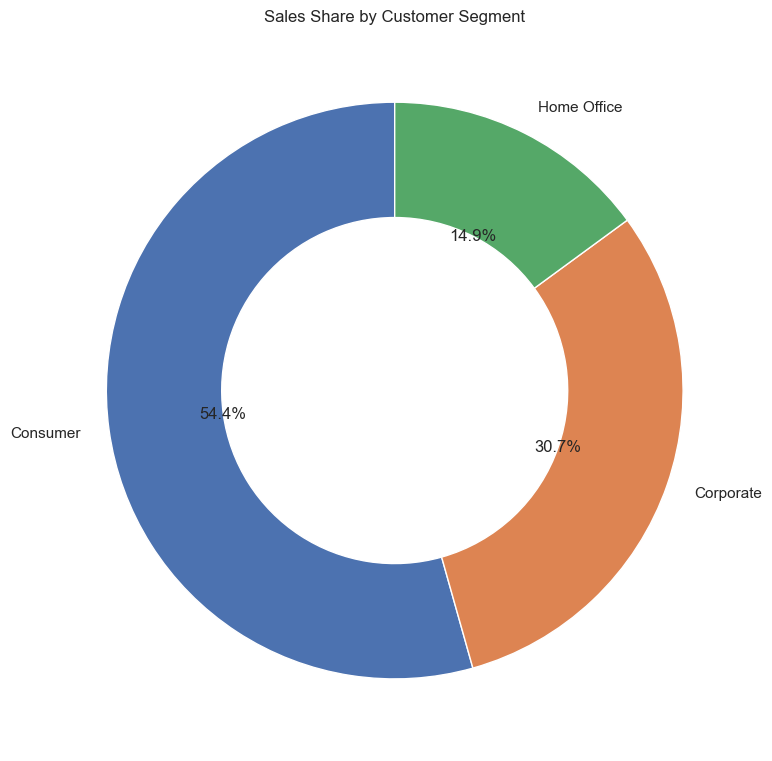

In [20]:
segment_sales = (
    df.groupby("Customer_Segment")["Sales"]
    .sum()
)

plt.figure(figsize=(8, 8))

plt.pie(
    segment_sales,
    labels=segment_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Sales Share by Customer Segment")

plt.tight_layout()
plt.savefig("../visualizations/06_sales_by_customer_segment.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 7. Sales Distribution by Product Category

Compare the distribution of transaction-level sales across product categories and identify variation and potential outliers.

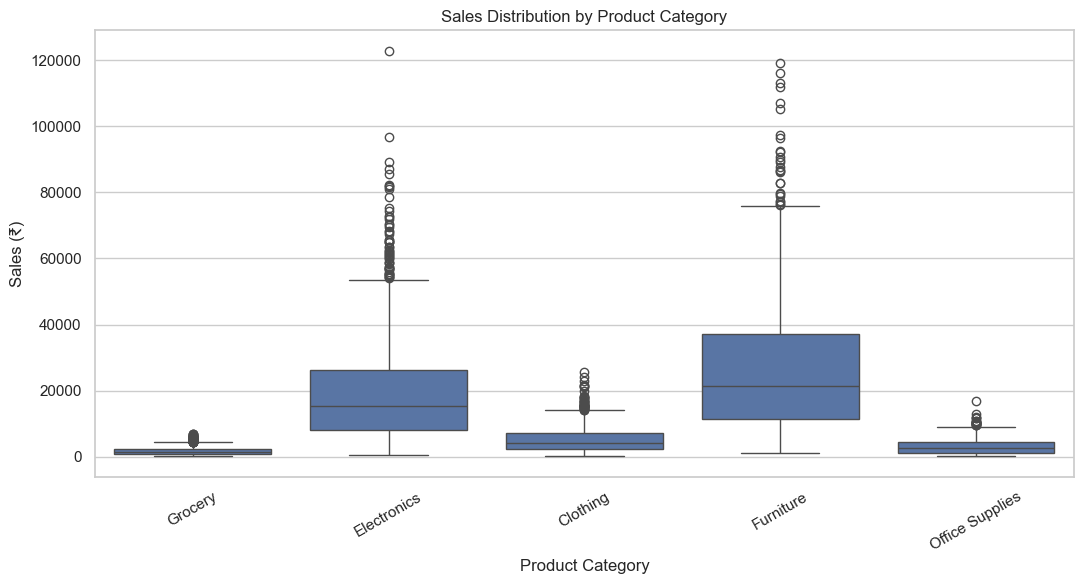

In [21]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Product_Category",
    y="Sales"
)

plt.title("Sales Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("../visualizations/07_sales_boxplot_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 8. Relationship Between Sales and Profit

Explore the relationship between sales revenue and profit to understand whether higher sales are generally associated with higher profitability.

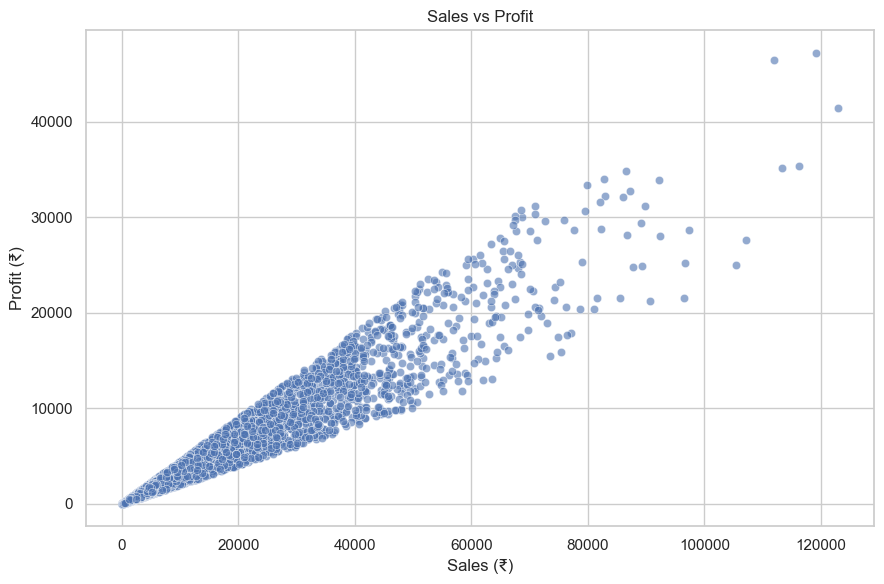

In [22]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    alpha=0.6
)

plt.title("Sales vs Profit")
plt.xlabel("Sales (₹)")
plt.ylabel("Profit (₹)")

plt.tight_layout()
plt.savefig("../visualizations/08_sales_vs_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 9. Relationship Between Discount and Profit

Investigate how discounts relate to profit and whether higher discounts are associated with lower profitability.

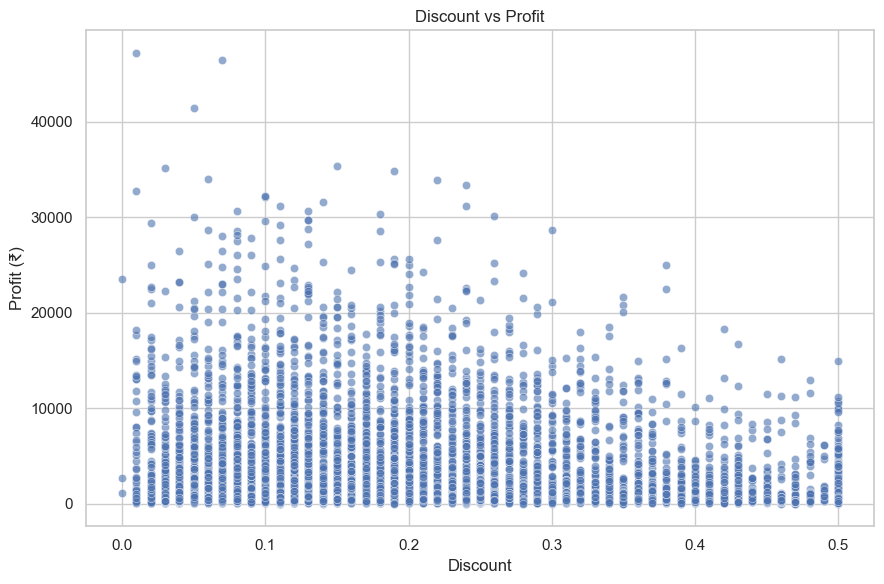

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.6
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit (₹)")

plt.tight_layout()
plt.savefig("../visualizations/09_discount_vs_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 10. Correlation Analysis

Examine correlations among key numerical variables to identify potential relationships between sales, profit, discounts, quantity, age, and income.

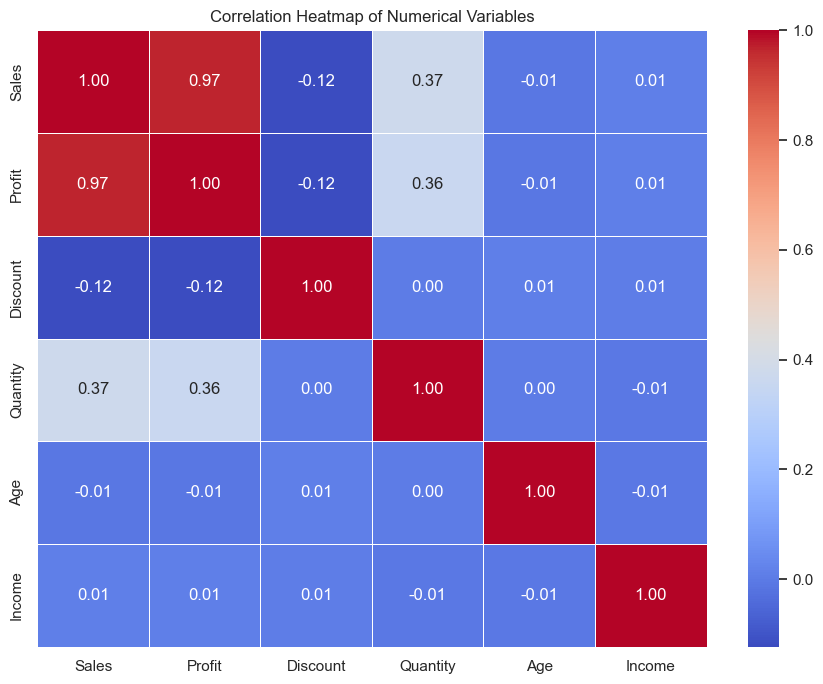

In [24]:
correlation_columns = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity",
    "Age",
    "Income"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.tight_layout()
plt.savefig("../visualizations/10_correlation_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 11. Average Sales by Product Category and Region

Compare average transaction-level sales across product categories and geographical regions to identify differences in purchasing performance.

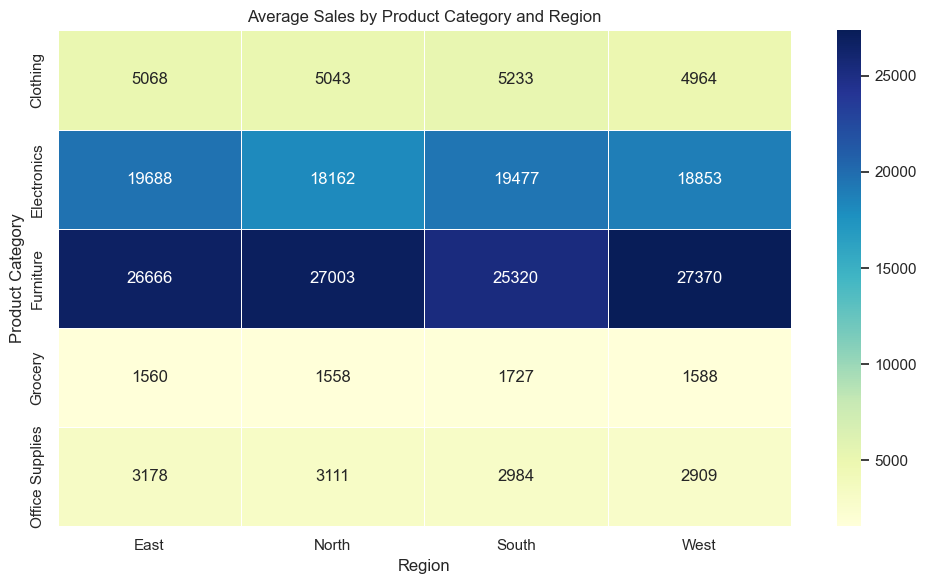

In [25]:
category_region_sales = df.pivot_table(
    values="Sales",
    index="Product_Category",
    columns="Region",
    aggfunc="mean"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    category_region_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Sales by Product Category and Region")
plt.xlabel("Region")
plt.ylabel("Product Category")

plt.tight_layout()
plt.savefig("../visualizations/11_category_region_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 12. Customer Satisfaction Analysis

Analyse the distribution of customer satisfaction levels to understand how customers evaluate their shopping experience.

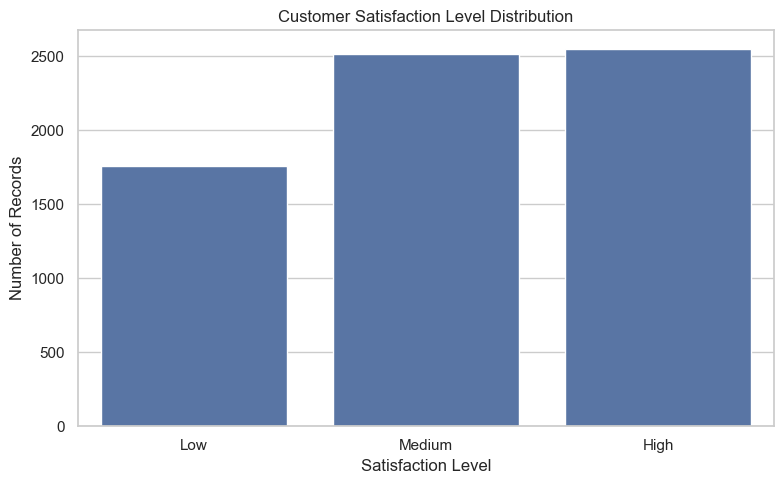

In [26]:
satisfaction_order = ["Low", "Medium", "High"]

satisfaction_counts = (
    df["Satisfaction_Level"]
    .value_counts()
    .reindex(satisfaction_order)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=satisfaction_counts.index,
    y=satisfaction_counts.values
)

plt.title("Customer Satisfaction Level Distribution")
plt.xlabel("Satisfaction Level")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("../visualizations/12_customer_satisfaction.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 13(a). Product Return Analysis

Compare returned and non-returned transactions to understand the overall frequency of product returns.

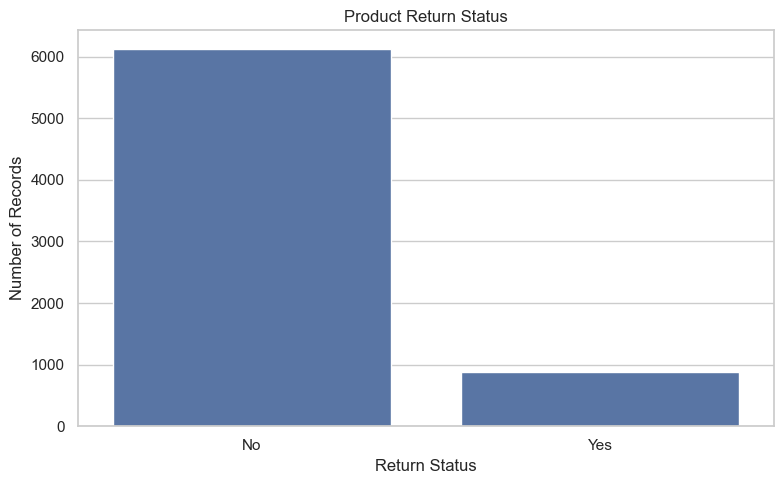

In [27]:
# Fixed: Using the correct column name 'Returned' from your dataset
return_counts = df["Returned"].value_counts(dropna=False)

plt.figure(figsize=(8, 5))

# Plot using seaborn barplot
sns.barplot(
    x=return_counts.index.astype(str),
    y=return_counts.values
)

plt.title("Product Return Status")
plt.xlabel("Return Status")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("../visualizations/13_product_return_analysis.png",
            dpi=300, bbox_inches="tight")
plt.show()


## 13(b). Business Performance Summary

Summarise the key business performance indicators calculated from the dataset.

In [28]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Profit Margin",
        "Average Order Value",
        "Total Transactions"
    ],
    "Value": [
        total_sales,
        total_profit,
        f"{profit_margin:.2f}%",
        average_order_value,
        df["Transaction_ID"].nunique()
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Sales,76731189.27
1,Total Profit,25127882.66
2,Profit Margin,32.75%
3,Average Order Value,10961.598467
4,Total Transactions,7000


## 14. Export Prepared Dataset

Save the prepared dataset with the additional date fields for use in Power BI and further analysis.

In [29]:
import os

# Create the data folder if it doesn't exist
os.makedirs("../data", exist_ok=True)

# Export the prepared dataset
output_path = os.path.abspath(
    "../data/Retail_Sales_Analysis_Ready.csv"
)

df.to_csv(output_path, index=False)

print("Dataset exported successfully!")
print("Saved location:", output_path)
print("Dataset shape:", df.shape)

Dataset exported successfully!
Saved location: C:\Users\hp\Desktop\data\Retail_Sales_Analysis_Ready.csv
Dataset shape: (7000, 28)


## 15. Project Summary

This project explored retail sales data covering 2023 and 2024. The analysis examined sales trends, regional and product category performance, customer demographics, profitability, discounts, customer satisfaction, and product returns.

The visualisations provide a foundation for identifying business patterns and generating recommendations. Key findings and business insights will be documented after reviewing the charts and their underlying data.